# Matching mothers and adult children with SQL

This runnable companion uses saved official NLSY79 extracts. After the one-time official source download, it rebuilds the analysis offline, inspects the matching queries, estimates an earnings IGE, and renders the two article figures. Read `../README.md` for acquisition commands, source definitions, selection rules and limitations.

In [1]:
from pathlib import Path
import sys, sqlite3, contextlib, io
import numpy as np
import pandas as pd
import statsmodels.api as sm
from IPython.display import display, Image

candidates = [Path.cwd(), *Path.cwd().parents, Path.cwd() / 'blog/posts/post6']
root = next(p for p in candidates if (p / 'code/match.sql').exists())
if not (root / 'data/raw/children.csv.gz').exists():
    raise FileNotFoundError('First run: python code/acquire.py from the post directory.')
sys.path.insert(0, str(root / 'code'))
import analyze, plot_results
with contextlib.redirect_stdout(io.StringIO()):
    summary = analyze.main()
connection = sqlite3.connect(root / 'data/processed/analysis.sqlite')
print(f"Common sample: {summary['children']:,} children and {summary['mothers']:,} mothers")

Common sample: 822 children and 669 mothers


## 1. Match the documented identifiers

Python standardizes reference-number columns, negative missing codes, military pay and the income reference year. SQL then builds the real-income and matched tables in `match.sql`. This query inspects the basic mother-child join. A mother can have several children; the child ID stays unique.

In [2]:
links = pd.read_sql_query('''
SELECT c.child_id, c.mother_id, c.birth_year AS child_birth_year,
       m.birth_year AS mother_birth_year
FROM children AS c
JOIN mothers AS m ON m.mother_id = c.mother_id
ORDER BY c.child_id;
''', connection)
assert links.child_id.is_unique
print('Linked children:', len(links))

Linked children: 11551


## 2. Aggregate income before joining generations

`real_income` contains each observed annual amount in 2020 dollars. `stage_income` assigns age windows. `GROUP BY` makes one average per person and window; genuine zero earnings remain in the mean, while missing amounts do not count as observations.

In [3]:
averages = pd.read_sql_query('''
SELECT generation, person_id, stage, AVG(real_income) AS mean_income,
       COUNT(DISTINCT income_year) AS observed_years
FROM stage_income
GROUP BY generation, person_id, stage;
''', connection)
assert not averages.duplicated(['generation', 'person_id', 'stage']).any()
display(averages.groupby(['generation','stage']).observed_years.agg(['count','median','min','max']))

paired = pd.read_sql_query('''
SELECT c.child_id, c.mother_id, m.mean_income AS mother_mean,
       a.mean_income AS adult_mean
FROM children AS c
JOIN stage_averages AS m ON m.person_id=c.mother_id AND m.stage='mother30s'
JOIN stage_averages AS a ON a.person_id=c.child_id AND a.stage='child30s';
''', connection)
assert paired.child_id.is_unique
print('Children with mother and adult income means:', len(paired))

count  median  min  max
generation stage                             
child      child20s    7979     4.0    1    5
           child30s    4273     2.0    1    5
mother     mother30s   4204     6.0    1    9

Children with mother and adult income means: 4245


## 3. Estimate the averaged specification

The complete SQL applies observation-count and positivity rules to create `matched`. All displayed models use the same children and the same adjustment vectors. The `log_mother` coefficient is the earnings IGE. Clustering by mother allows siblings to share residual influences.

In [4]:
sample = pd.read_sql_query('SELECT * FROM matched ORDER BY child_id', connection)
x = pd.DataFrame({
    'log_mother': np.log(sample.mother_mean),
    'mother_age': sample.mother_mean_age-35,
    'child_age': sample.adult_mean_age-35,
    'female': (sample.child_sex==2).astype(int),
    'birth_year': sample.child_birth_year-1978,
})
fit = sm.OLS(np.log(sample.adult_mean), sm.add_constant(x)).fit(
    cov_type='cluster', cov_kwds={'groups': sample.mother_id}, use_t=True)
expected = next(r['ige'] for r in summary['estimates'] if r['specification']=='average_both')
assert abs(fit.params['log_mother']-expected)<1e-10
print(f"Averaged earnings IGE: {fit.params['log_mother']:.3f}")
display(fit.conf_int().loc[['log_mother']].rename(columns={0:'95% lower',1:'95% upper'}))

Averaged earnings IGE: 0.103


,95% lower,95% upper
log_mother,0.043802,0.162517


## 4. Compare measurements and ages

The plotting module contains the editable Matplotlib code; it reads the saved estimates instead of manually entered numbers. Both figures use identical pairs. Wider intervals and the paired contrasts matter: changing a point estimate does not by itself establish a population difference.

Saved both figures as SVG and PNG.


,specification,ige,ci_low,ci_high,children,mothers
0,annual_both,0.097198,0.038523,0.155873,822,669
1,average_mother,0.113296,0.042260,0.184332,822,669
2,average_both,0.103160,0.043802,0.162517,822,669
3,young_annual,0.090193,0.028871,0.151514,822,669
4,young_average,0.087039,0.042431,0.131647,822,669
5,age20,0.063432,-0.017310,0.144174,822,669
6,age25,0.124598,0.067621,0.181575,822,669
7,age30,0.096678,0.027006,0.166351,822,669
8,age35,0.128912,0.057964,0.199860,822,669


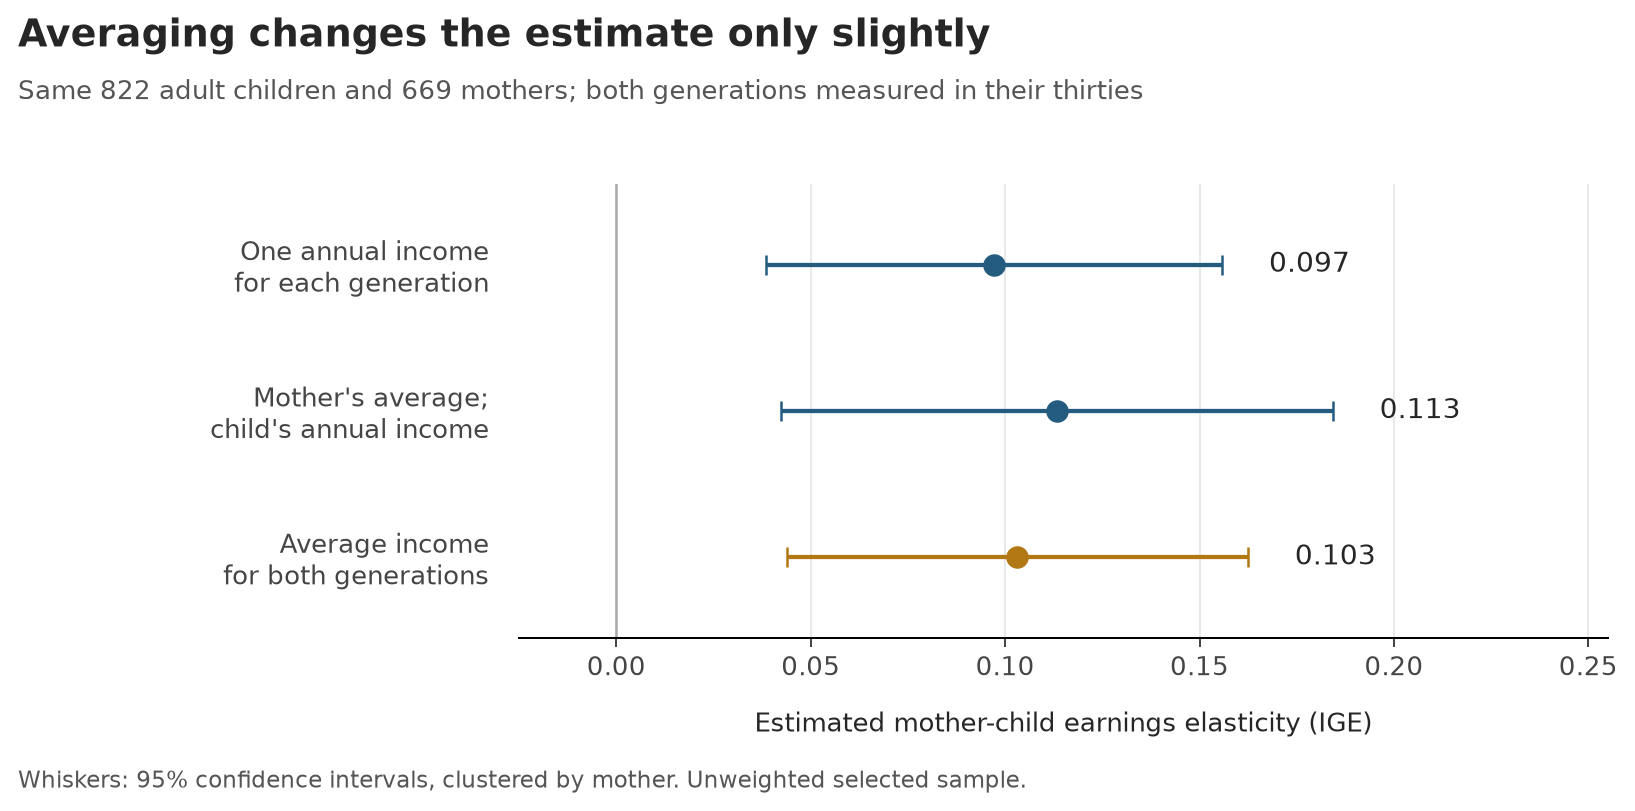

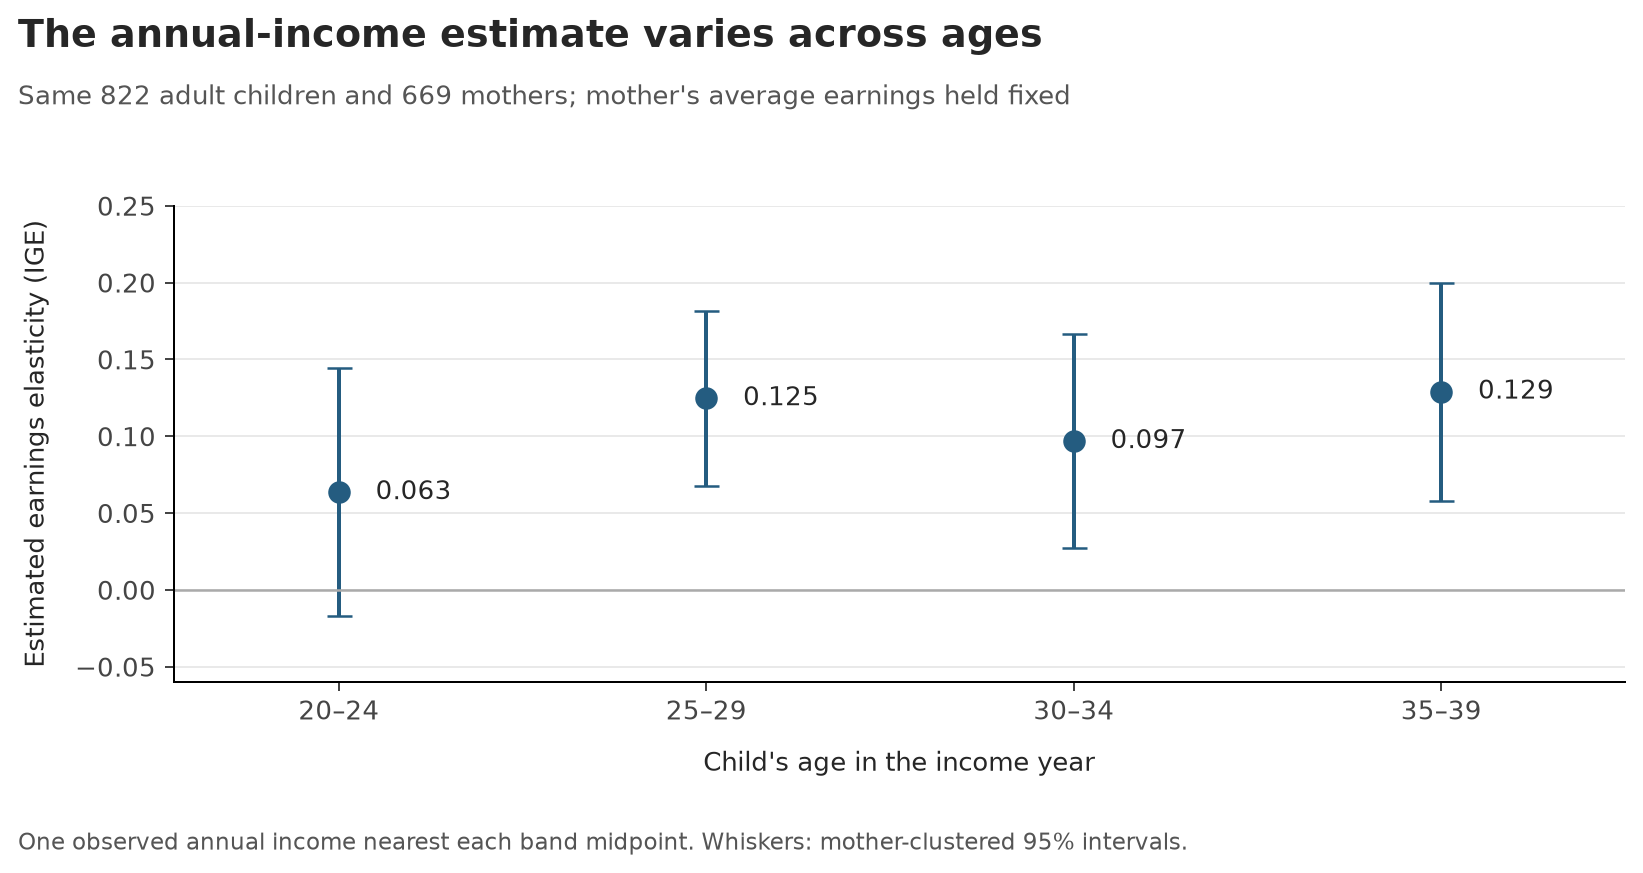

,comparison,difference,standard_error,ci_low,ci_high
0,average_both minus annual_both,0.005962,0.021610,-0.036470,0.048394
1,average_mother minus annual_both,0.016098,0.021026,-0.025186,0.057382
2,average_both minus average_mother,-0.010136,0.014817,-0.039229,0.018957
3,average_mother minus young_annual,0.023103,0.038422,-0.052340,0.098547
4,average_both minus young_average,0.016121,0.022784,-0.028617,0.060859
5,age35 minus age20,0.065480,0.045333,-0.023533,0.154493


In [5]:
plot_results.main()
estimates = pd.read_csv(root / 'results/estimates.csv')
display(estimates[['specification','ige','ci_low','ci_high','children','mothers']])
display(Image(filename=str(root / 'results/annual-versus-average.png'), width=900))
display(Image(filename=str(root / 'results/income-age.png'), width=900))
display(pd.read_csv(root / 'results/differences.csv'))
connection.close()

## What these results describe

This is an unweighted selected sample, not a national mobility estimate. The age profile is exploratory; age and calendar period change together. Averages of observed years can reduce temporary fluctuations, but neither an average nor an older observation is known lifetime income. The larger broad-window sensitivity sample is retained in `results/broad_window_sensitivity.csv`.

Sources: [NLS cohort downloads](https://www.nlsinfo.org/content/access-data-investigator/accessing-data-cohorts), [mother-child linkage](https://www.nlsinfo.org/content/cohorts/nlsy79-children/using-and-understanding-the-data/linking-children-young-adults-and), [YA income definitions](https://www.nlsinfo.org/content/cohorts/nlsy79-children/topical-guide/income/introduction), [CPI-U annual table](https://www.minneapolisfed.org/about-us/monetary-policy/inflation-calculator/consumer-price-index-1913-), and [Haider and Solon](https://public.websites.umich.edu/~gsolon/workingpapers/haider.pdf).